In [93]:
import pandas as pd
from pyalexutil import extract_authorids

preprint_df = pd.read_pickle("./data/biorxiv/biorxiv_openalex.pkl") 
preprint_df["author_id"] = preprint_df["authorships"].apply(extract_authorids)
preprint_df.loc[:, "id"] = preprint_df["id"].str.replace("https://openalex.org/", "", regex=False)

preprint_df = preprint_df.set_index("id")
preprint_df.head()

,counts_by_year,publication_year,publication_date,authorships,primary_topic,cited_by_count,doi,locations,locations_count,author_id
id,,,,,,,,,,
W3202105508,"[{'year': 2025, 'cited_by_count': 68}, {'year'...",2021,2021-10-04,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10044', 'display...",2744,https://doi.org/10.1101/2021.10.04.463034,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5017082774, A5050183837, A5062883663, A50266..."
W3099862724,"[{'year': 2025, 'cited_by_count': 39}, {'year'...",2016,2016-06-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10887', 'display...",2527,https://doi.org/10.1101/060012,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5080846001, A5037013243, A5109478513, A51115..."
W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5080595259, A5030359300, A5055476069, A50579..."
W2538509698,"[{'year': 2024, 'cited_by_count': 258}, {'year...",2016,2016-10-15,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1568,https://doi.org/10.1101/081257,"[{'is_oa': True, 'landing_page_url': 'https://...",1,[A5077667471]
W2952535963,"[{'year': 2024, 'cited_by_count': 87}, {'year'...",2014,2014-02-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1382,https://doi.org/10.1101/002824,"[{'is_oa': True, 'landing_page_url': 'https://...",2,"[A5022280742, A5014255302, A5029601108]"


In [ ]:
import polars as pl

topic_df = pl.read_ndjson("/disks/qnap3/users/23-miura/openalex-snapshot/processed_json/works/primary_topic_id.jsonl.gz")
author_df = pl.read_ndjson("/disks/qnap3/users/23-miura/openalex-snapshot/processed_json/works/author_id.jsonl.gz")
type_df = pl.read_ndjson("/disks/qnap3/users/23-miura/openalex-snapshot/processed_json/works/type.jsonl.gz")
language_df = pl.read_ndjson("/disks/qnap3/users/23-miura/openalex-snapshot/processed_json/works/language.jsonl.gz")

topic_table = pl.read_csv("./data/topic_field_subfield_table.tsv", separator="\t")
bio_topics = ["T" + str(t) for t in topic_table.filter(pl.col("domain_name") == "Life Sciences").get_column("topic_id").to_list()]

In [140]:
counts_by_year_df = pl.read_ndjson("/disks/qnap3/users/23-miura/openalex-snapshot/processed_json/works/counts_by_year.jsonl.gz")

In [90]:
topic_df.columns

['work_id', 'topic_id']

In [ ]:
# review, article
works_df = (
    topic_df
    .join(type_df, on="work_id", how="inner")
    .join(language_df, on="work_id", how="inner")
    .join(author_df, on="work_id", how="inner")
).filter(
    (pl.col("topic_id").is_in(bio_topics)) &
    (pl.col("type").is_in(["review", "article"])) &
    (pl.col("language")=="en") &
    (~pl.col("work_id").is_in(preprint_df.index)) 
)
works_df.height
# 19317210

19317210

In [ ]:
n = 5

author_df_ = works_df.select(["author_id", "work_id"]).explode("author_id").filter(pl.col("author_id")!="A9999999999")

valid_authors = (
    author_df_
      .group_by("author_id")
      .len()
      .filter(pl.col("len") >= n)
)

valid_authors_work_df = (
    author_df_
    .join(valid_authors, on="author_id")
    .select("work_id")
    .unique()
    .join(works_df, on="work_id")
)
valid_authors.height, valid_authors.sort("len")

3083391

In [107]:
valid_authors_work_df

work_id,topic_id,type,language,author_id
str,str,str,str,list[str]
"""W2361936369""","""T13221""","""article""","""en""","[""A5074456918""]"
"""W2384984766""","""T13221""","""article""","""en""","[""A5100667347""]"
"""W2242569363""","""T11072""","""article""","""en""","[""A5044217009"", ""A5037765593"", … ""A5073119685""]"
"""W2994154995""","""T13221""","""article""","""en""","[""A5100645092"", ""A5062791391"", … ""A5027149981""]"
"""W2064713562""","""T12321""","""article""","""en""","[""A5091393437""]"
…,…,…,…,…
"""W4408055301""","""T14285""","""article""","""en""","[""A5101807404"", ""A5091488733"", … ""A5100446064""]"
"""W4408055392""","""T10836""","""article""","""en""","[""A5104328975"", ""A5011640182"", … ""A5051418279""]"
"""W4408055419""","""T10887""","""article""","""en""","[""A5045412670"", ""A5092092560"", … ""A5016104736""]"


In [110]:
valid_authors_work_df.write_parquet("./data/valid_authors_work_df.parquet")
valid_authors.write_parquet("./data/valid_authors.parquet")

# Preprint Author Ratio

In [111]:
import pandas as pd
from pyalexutil import extract_authorids

preprint_df = pd.read_pickle("./data/biorxiv/biorxiv_openalex.pkl") 
preprint_df["author_id"] = preprint_df["authorships"].apply(extract_authorids)

preprint_df.head()

,id,counts_by_year,publication_year,publication_date,authorships,primary_topic,cited_by_count,doi,locations,locations_count,author_id
0,https://openalex.org/W3202105508,"[{'year': 2025, 'cited_by_count': 68}, {'year'...",2021,2021-10-04,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10044', 'display...",2744,https://doi.org/10.1101/2021.10.04.463034,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5017082774, A5050183837, A5062883663, A50266..."
1,https://openalex.org/W3099862724,"[{'year': 2025, 'cited_by_count': 39}, {'year'...",2016,2016-06-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10887', 'display...",2527,https://doi.org/10.1101/060012,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5080846001, A5037013243, A5109478513, A51115..."
2,https://openalex.org/W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5080595259, A5030359300, A5055476069, A50579..."
3,https://openalex.org/W2538509698,"[{'year': 2024, 'cited_by_count': 258}, {'year...",2016,2016-10-15,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1568,https://doi.org/10.1101/081257,"[{'is_oa': True, 'landing_page_url': 'https://...",1,[A5077667471]
4,https://openalex.org/W2952535963,"[{'year': 2024, 'cited_by_count': 87}, {'year'...",2014,2014-02-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1382,https://doi.org/10.1101/002824,"[{'is_oa': True, 'landing_page_url': 'https://...",2,"[A5022280742, A5014255302, A5029601108]"


,author_id,count
0,A5032850756,185
1,A5013184354,156
2,A5083128670,146
3,A5103076360,143
4,A5047963275,137
...,...,...
904717,A5113244539,1
904718,A5012384958,1
904719,A5113952350,1
904720,A5086462736,1


In [123]:
preprint_authors = pl.from_pandas(
    preprint_df["author_id"].explode().value_counts().reset_index().rename(
        columns={"count": "preprint_count"}
    )
)
preprint_authors

author_id,preprint_count
str,i64
"""A5032850756""",185
"""A5013184354""",156
"""A5083128670""",146
"""A5103076360""",143
"""A5047963275""",137
…,…
"""A5113244539""",1
"""A5012384958""",1
"""A5113952350""",1


In [124]:
bio_authors = valid_authors_work_df.get_column("author_id").explode().value_counts()
bio_authors

author_id,count
str,u32
"""A5031895723""",1
"""A5112667866""",1
"""A5108378614""",1
"""A5113183849""",1
"""A5011410652""",8
…,…
"""A5040430655""",1
"""A5062164792""",1
"""A5055449552""",12


In [125]:
all_authors = preprint_authors.join(
    bio_authors, on="author_id", how="full"
)
print(bio_authors.height, preprint_authors.height, all_authors.drop_nulls().height)

all_authors = all_authors.fill_null(0)

12757158 904722 771240


In [126]:
bins_x = [5,10,20,50,100,200, 500, 1000, 5000]
bins_y = [0, 1, 2, 3,  5, 10,  20,   50,  100]
col1 = "preprint_count_bins"
col2 = "count_bins"
labels=[str(i) for i in range(len(bins_x) + 1)]
cuts = all_authors.select(
    pl.col("preprint_count").cut(breaks=bins_y, left_closed=True, labels=labels).alias("preprint_count_bins"),
    pl.col("count").cut(breaks=bins_x, left_closed=True, labels=labels).alias("count_bins")
)
cuts_count = (
    cuts.group_by([col1, col2])
    .len()
    .pivot(
        values="len",
        index=col1,
        columns=col2,
        aggregate_function=None,  # len()で集約済みなので不要
    )
    .fill_null(0)  # 出現しない組み合わせは0にする
)

sorted_columns = [col1] + sorted(c for c in cuts_count.columns if c != col1)
cuts_count = cuts_count.select(sorted_columns).sort(by=col1)

cuts_count

/tmp/ipykernel_612745/354385904.py:11: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  cuts.group_by([col1, col2])


preprint_count_bins,0,1,2,3,4,5,6,7,8
cat,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""1""",9414675,1313125,713029,416810,100100,24511,3488,162,18
"""2""",304683,79275,69123,61439,21867,7251,1236,34,5
"""3""",56056,28780,27251,26075,10858,4117,857,32,3
"""4""",25434,22831,23650,24499,10836,4648,1196,47,2
"""5""",5947,10007,15417,19602,9996,4852,1440,85,6
"""6""",436,957,2729,6669,4992,3049,1067,72,5
"""7""",17,43,181,1030,1525,1369,727,58,6
"""8""",0,0,0,11,35,124,129,22,1
"""9""",0,0,0,0,1,5,15,9,1


/home/c-miura/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_612745/1282244493.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_text = count_matrix.applymap(to_sci_notation)


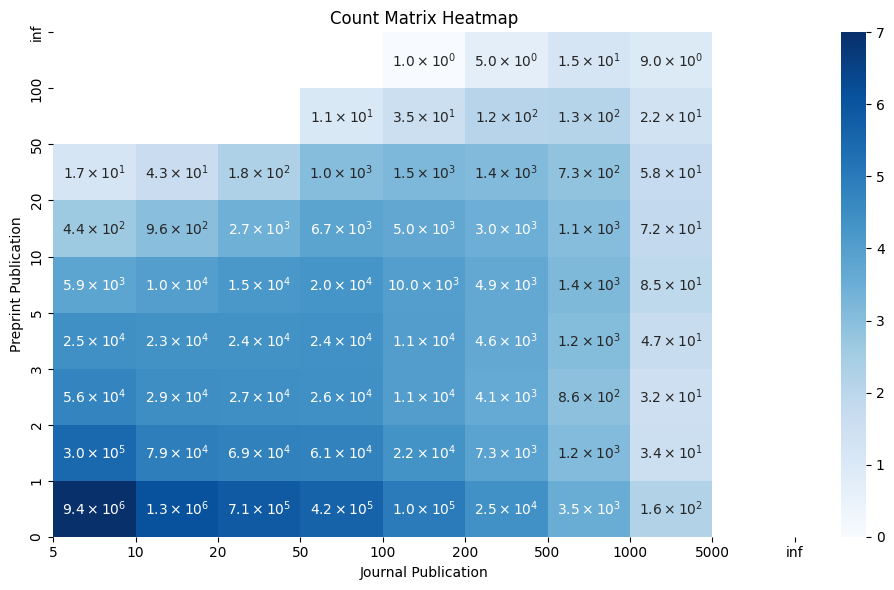

In [132]:
import numpy as np
count_matrix = cuts_count[labels[:8]].to_pandas()

start = 0
count_matrix = count_matrix.iloc[start:,start:] 
count_matrix_log = np.log10(count_matrix)

import seaborn as sns
import matplotlib.pyplot as plt

# --- 上で作った count_matrix を使う ---

def to_sci_notation(x):
    if x == 0:
        return "0"
    exponent = int(np.floor(np.log10(x)))
    base = x / (10 ** exponent)
    return f"${base:.1f} \\times 10^{{{exponent}}}$"

annot_text = count_matrix.applymap(to_sci_notation)


plt.figure(figsize=(10, 6))
sns.heatmap(
    count_matrix_log,
    annot=annot_text,       # 各マスに数字も表示
    fmt="",           # 数字のフォーマット（整数）
    cmap="Blues",       # カラーマップ（自由に変えられる）
    vmin=0, vmax=7,  # カラーマップの最小値と最大値
)

plt.title("Count Matrix Heatmap")
plt.xlabel("Journal Publication")
plt.ylabel("Preprint Publication")
xtick_labels = bins_x[start:] + ["inf"]
ytick_labels = bins_y[start:] + ["inf"]
plt.xticks(range(len(xtick_labels)), xtick_labels)
plt.yticks(range(len(ytick_labels)), ytick_labels)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

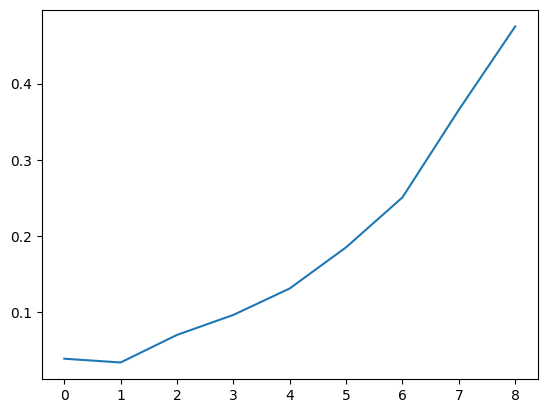

In [197]:
ratio = []
t = 1
for threshold in bins:
    ratio.append(
        all_authors.filter(
        pl.col("preprint_count") >= t,
        pl.col("count") >= threshold,
    ).height / all_authors.filter(
        pl.col("count") >= threshold
    ).height
    )
plt.plot(ratio)

# Yearly Citation Count Analysis

In [133]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

def yearly_sparse(works_df, years=range(2012, 2025)):
    # counts_by_yearがある行だけ対象
    works = works_df.dropna()

    # 年と列インデックスの対応
    year_to_col = {year: idx for idx, year in enumerate(years)}
    n_years = len(years)

    # まずデータを一気に集める
    data = []
    rows = []
    cols = []

    for work_idx, counts_by_year in enumerate(works):
        for d in counts_by_year:
            year = d["year"]
            if year in year_to_col:
                data.append(d["cited_by_count"])
                rows.append(work_idx)
                cols.append(year_to_col[year])

    # numpy arrayに変換
    data = np.array(data, dtype=np.int32)
    rows = np.array(rows, dtype=np.int32)
    cols = np.array(cols, dtype=np.int32)

    # まとめてcsr_matrixにする！
    sparse_matrix = csr_matrix((data, (rows, cols)), shape=(len(works), n_years))

    return sparse_matrix, works.index

def calc_work_author_matrix(authorship_df, work_ids):
    authorship_sub = authorship_df.reindex(work_ids)

    from itertools import chain
    all_author_ids = sorted(set(chain.from_iterable(authorship_sub)))
    author_to_index = {author: idx for idx, author in enumerate(all_author_ids)}

    all_pairs = [
        (row_idx, author)
        for row_idx, authors in enumerate(authorship_sub)
        for author in authors
    ]

    row = np.array([row_idx for row_idx, author in all_pairs])
    col = np.array([author_to_index[author] for row_idx, author in all_pairs])
    data = np.ones(len(row), dtype=np.int8)

    work_author_matrix = csr_matrix(
        (data, (row, col)),
        shape=(len(work_ids), len(all_author_ids))
    )
    return work_author_matrix, all_author_ids


In [ ]:
counts_by_year_df = pl.read_ndjson("/disks/qnap3/users/23-miura/openalex-snapshot/processed_json/works/counts_by_year.jsonl.gz")

In [141]:
# works_df = pd.read_parquet("./data/bio_works_df_valid_author_id.parquet")

# works_df["first_author"] = works_df["author_id"].str[0].to_list()
# works_df["last_author"] = works_df["author_id"].str[0].to_list()

works_df_ = valid_authors_work_df.join(
    counts_by_year_df, on="work_id", how="inner"
).filter(
    pl.col("counts_by_year").len()>0
).to_pandas()
    # [works_df["counts_by_year"].str.len()>0].dropna(subset="last_author").set_index("work_id")

In [153]:
w = works_df_.sample(frac=1)
counts_by_year = w["counts_by_year"]
authorship = w["author_id"]

In [154]:
year_range = list(range(2012, 2025))
work_year_matrix, work_ids = yearly_sparse(counts_by_year)
work_author_matrix, all_author_ids = calc_work_author_matrix(authorship, work_ids)
author_year_matrix = work_author_matrix.T @ work_year_matrix  # shape=(著者数, 年数)

author_year_df = pd.DataFrame(
    author_year_matrix.toarray(),
    index=all_author_ids,
    columns=year_range
).reindex(valid_authors.get_column("author_id").to_list()).dropna()

print(author_year_df.shape[0])
author_year_df.to_pickle("./data/author_year_df_winsed.pkl")

9518719


In [157]:
author_year_df.reindex(valid_authors.get_column("author_id").to_list()).dropna().to_pickle("./data/author_year_df_reindex.pkl")

In [158]:
author_year_df.reindex(valid_authors.get_column("author_id").to_list()).dropna().shape[0]

3006904

In [38]:
import pandas as pd
from pyalexutil import extract_authorids

# preprint_df = pd.read_pickle("./data/biorxiv/biorxiv_openalex.pkl") 
# preprint_df["author_id"] = preprint_df["authorships"].apply(extract_authorids)
# preprint_df.loc[:, "id"] = preprint_df["id"].str.replace("https://openalex.org/", "", regex=False)

# preprint_df = preprint_df.set_index("id")

# preprint_df["first_author"] = preprint_df["author_id"].apply(lambda x: [x[0]] if len(x) > 0 else None)
# preprint_df["last_author"] = preprint_df["author_id"].apply(lambda x: [x[-1]] if  len(x) > 0 else None)

preprint_df_ = preprint_df[preprint_df["counts_by_year"].str.len() > 0].dropna(subset=["last_author"])

In [39]:
preprint_df_.head()

,counts_by_year,publication_year,publication_date,authorships,primary_topic,cited_by_count,doi,locations,locations_count,author_id,first_author,last_author
id,,,,,,,,,,,,
W3202105508,"[{'year': 2025, 'cited_by_count': 68}, {'year'...",2021,2021-10-04,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10044', 'display...",2744,https://doi.org/10.1101/2021.10.04.463034,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5017082774, A5050183837, A5062883663, A50266...",[A5017082774],[A5005349213]
W3099862724,"[{'year': 2025, 'cited_by_count': 39}, {'year'...",2016,2016-06-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10887', 'display...",2527,https://doi.org/10.1101/060012,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5080846001, A5037013243, A5109478513, A51115...",[A5080846001],[A5043105503]
W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,https://doi.org/10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1,"[A5080595259, A5030359300, A5055476069, A50579...",[A5080595259],[A5029475781]
W2538509698,"[{'year': 2024, 'cited_by_count': 258}, {'year...",2016,2016-10-15,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1568,https://doi.org/10.1101/081257,"[{'is_oa': True, 'landing_page_url': 'https://...",1,[A5077667471],[A5077667471],[A5077667471]
W2952535963,"[{'year': 2024, 'cited_by_count': 87}, {'year'...",2014,2014-02-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1382,https://doi.org/10.1101/002824,"[{'is_oa': True, 'landing_page_url': 'https://...",2,"[A5022280742, A5014255302, A5029601108]",[A5022280742],[A5029601108]


In [40]:
preprint_counts_by_year = preprint_df_["counts_by_year"] 
preprint_authorship_df = preprint_df_["last_author"]

In [ ]:
preprint_year_matrix, preprint_ids = yearly_sparse(preprint_counts_by_year, years=year_range)
preprint_author_matrix, all_preprint_author_ids = calc_work_author_matrix(preprint_authorship_df, preprint_ids)
author_year_matrix_prperint = preprint_author_matrix.T @ preprint_year_matrix  # shape=(著者数, 年数)

preprint_year_df = pd.DataFrame(
    author_year_matrix_prperint.toarray(),
    index=all_preprint_author_ids,
    columns=year_range
)

print(preprint_year_df.shape[0])
preprint_year_df.to_pickle("./data/author_year_df_preprint_winsed.pkl")

66491


# Preferential Attachment

In [159]:
author_year_df = pd.read_pickle("./data/author_year_df_reindex.pkl")
preprint_year_df = pd.read_pickle("./data/author_year_df_preprint.pkl")
# author_year_df = pd.read_pickle("./data/author_year_df_firstauthor.pkl")
# preprint_year_df = pd.read_pickle("./data/author_year_df_preprint_firstauthor.pkl")
# author_year_df = pd.read_pickle("./data/author_year_df_lastauthor.pkl")
# preprint_year_df = pd.read_pickle("./data/author_year_df_preprint_lastauthor.pkl")

In [160]:
preprint_author_indices = list(set(preprint_year_df.index) & set(author_year_df.index))

In [161]:
author_yearly_cum

,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
A5017936335,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5001305738,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5007033895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5108257037,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5071586257,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
A5002249161,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5028805574,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5022282438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A5061651263,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [162]:
def cited_probability(c1, c2):
    c1.name = "c1"
    total_new_cites = c2.sum() - c1.sum()
    probability = (c2 - c1) / total_new_cites
    probability.name = "probability"
    df = pd.concat([c1,c2, probability], axis=1)
    
    pi = df.groupby('c1')['probability'].mean()
    return pi

def cited_probability_delta(c0, delta_c):
    c0.name = "c"
    total_new_cites = delta_c.sum()
    probability = delta_c / total_new_cites
    probability.name = "probability"
    df = pd.concat([c0, delta_c, probability], axis=1)
    
    pi = df.groupby('c')['probability'].mean()
    return pi

author_yearly_cum = author_year_df.cumsum(axis=1)
preprint_yearly_cum = preprint_year_df.cumsum(axis=1)

pi_j = cited_probability(author_yearly_cum[2022], author_yearly_cum[2023])
pi_p = cited_probability_delta(author_yearly_cum[2022].reindex(preprint_author_indices), preprint_year_df.reindex(preprint_author_indices)[2023])
pi_n = cited_probability(preprint_yearly_cum[2022], preprint_yearly_cum[2023])

['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


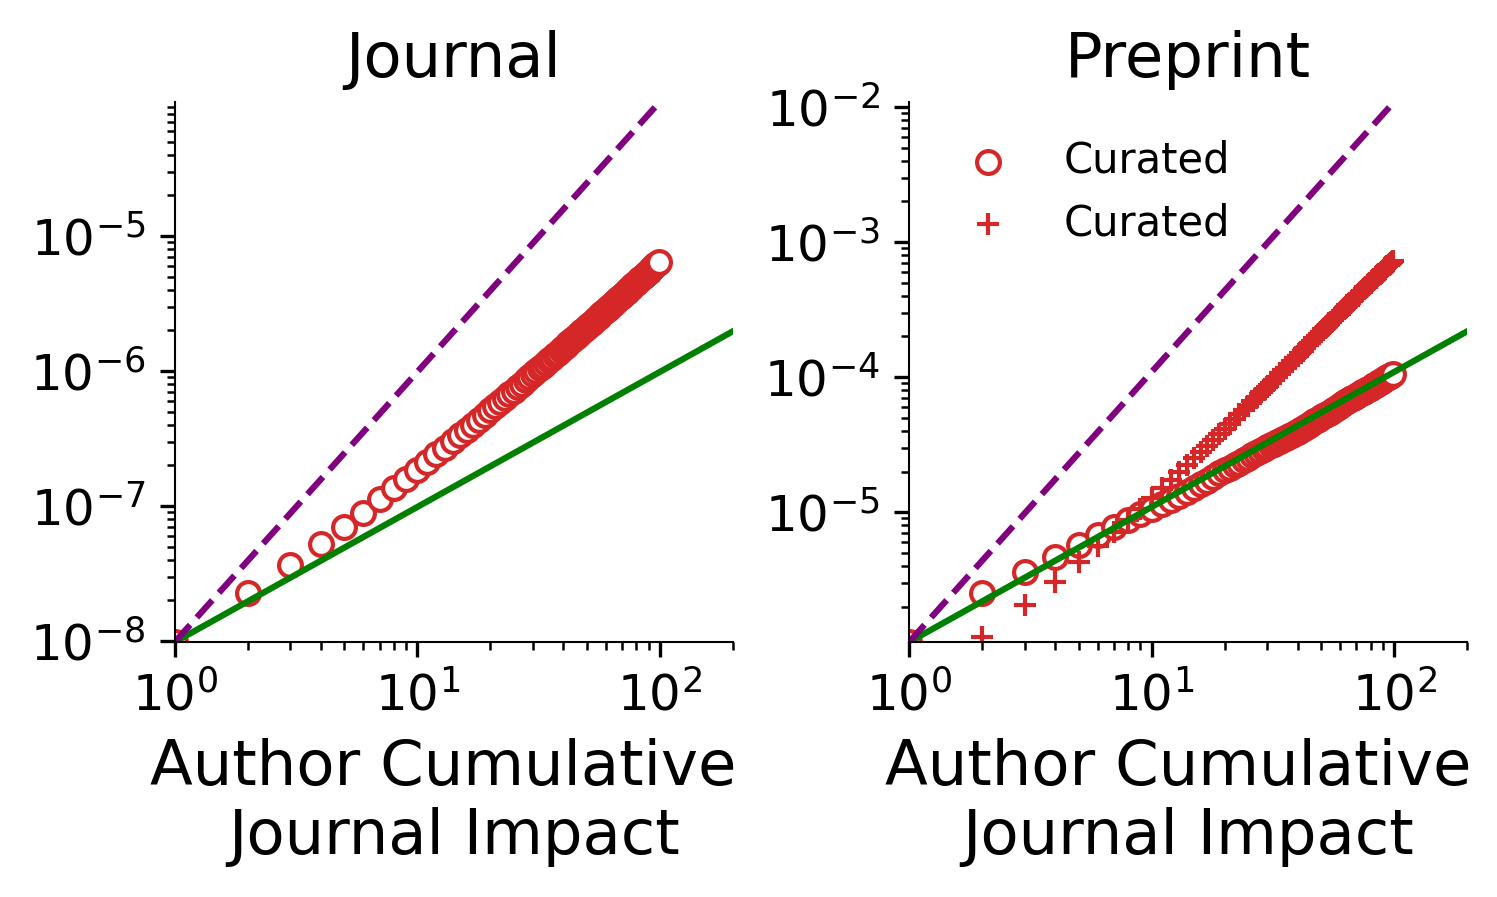

In [164]:
from matplotlib import pyplot as plt
import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rc('axes', titlesize=15, labelsize=15)      # Title font size
plt.rc('xtick', labelsize=12)     # X-axis tick font size
plt.rc('ytick', labelsize=12)     # Y-axis tick font size
plt.rc('legend', fontsize=13)     # Legend font sizplt

print(plt.rcParams['axes.prop_cycle'].by_key()['color'])
print(plt.rcParams['axes.prop_cycle'].by_key()['color'])
fig, ax = plt.subplots(1,2, figsize=(5,3))
fig.subplots_adjust(hspace=0.1, wspace=0.4)

def plot_citation_probability(ax, pi, **kwargs):
    ax.spines[['right', 'top']].set_visible(False)
    ax.tick_params(which='both', top=False, right=False)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1, 2e+2)

    pi = pi[pi.index > 0]
    scale = pi.loc[1]

    max_x = 10**4
    x = np.linspace(1, max_x, max_x) # 
    if kwargs.get('multi', None) is None:
        ax.plot(x, x * scale, linestyle="-", color="green", linewidth=1.5)
        ax.plot(x, np.square(x) * scale, linestyle="--", color="purple", linewidth=1.5)
        ax.set_ylim(pi.loc[1], pi.loc[1]* max_x)
        # ax.plot(x, [scale] *max_x, linestyle="-", color="gray")
        # ax.plot(x, x * scale*10, linestyle="--", color="green")
        # ax.set_ylim(scale/10, scale* max_x)

    kwargs.pop('multi', None)
    pi = pi[pi.index < 10**2]
    ax.scatter(pi.index, pi.values.cumsum(), s=30, **kwargs)
    # ax.scatter(pi.index, pi.values, s=30, **kwargs)

plot_citation_probability(ax[0], pi_j, edgecolor=plt.rcParams['axes.prop_cycle'].by_key()['color'][3], color="white", label="Curated", marker = "o")
plot_citation_probability(ax[1], pi_p, edgecolor=plt.rcParams['axes.prop_cycle'].by_key()['color'][3], color="white", label="Curated", marker = "o")
plot_citation_probability(ax[1], pi_n, color=plt.rcParams['axes.prop_cycle'].by_key()['color'][3], label="Curated", marker = "+", multi=True)
ax[0].set_title("Journal")
ax[0].set_xlabel("Author Cumulative \nJournal Impact")
ax[1].legend(loc="upper left", fontsize=10, frameon=False)
ax[1].set_xlabel("Author Cumulative \nJournal Impact")
ax[1].set_title("Preprint")
plt.tight_layout()

# Top 1% author citation share

In [180]:
import pandas as pd
import numpy as np

author_year_df = pd.read_pickle("./data/author_year_df_reindex.pkl")
preprint_year_df = pd.read_pickle("./data/author_year_df_preprint.pkl")


# 処理
def zero_to_nan_before_first_nonzero(row):
    mask = (row != 0)
    if not mask.any():
        # 全部0の場合はNoneを返す
        return pd.Series([None] * len(row), index=row.index)
    first_nonzero_idx = mask.idxmax()  # 最初にTrueになる列名
    row.iloc[:row.index.get_loc(first_nonzero_idx)] = np.nan
    return row


author_year_df = author_year_df.apply(zero_to_nan_before_first_nonzero)
preprint_year_df = preprint_year_df.apply(zero_to_nan_before_first_nonzero)

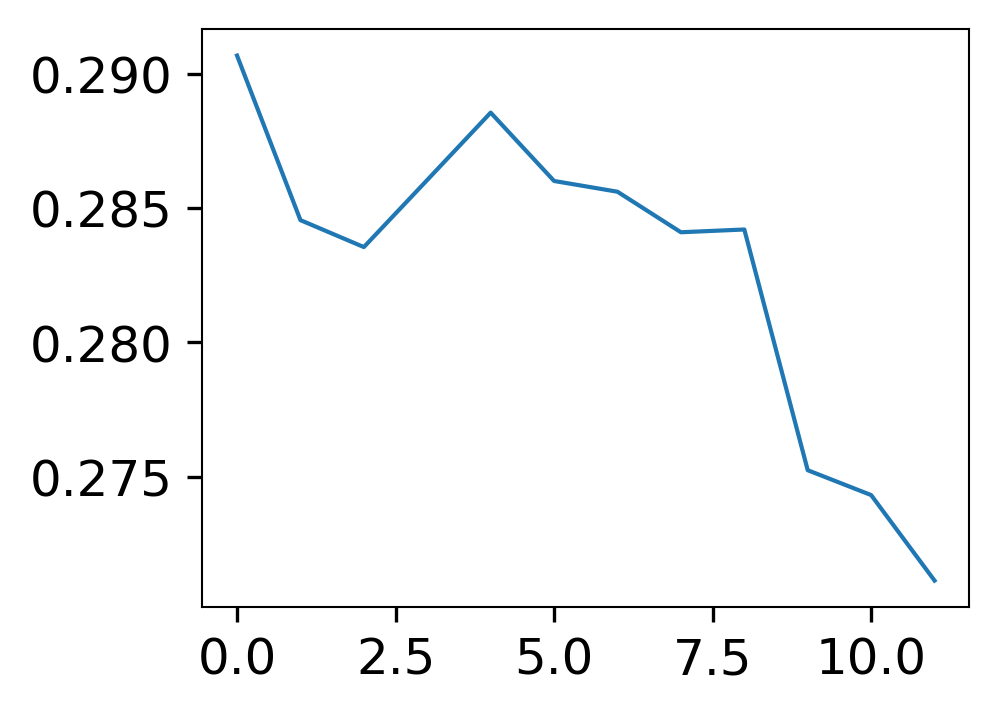

In [184]:
def plot_citation_monopoly(data):
    return data[data>data.quantile(0.99)].sum() / data.sum()

ratio = []
for i in range(2013, 2025):
    ratio.append(plot_citation_monopoly(author_year_df[i].dropna()))
plt.plot(range(2013, 2025), ratio)

In [ ]:
i = 2014
author_year_df
(author_year_df.sum(axis=1) == 0).sum()

1506

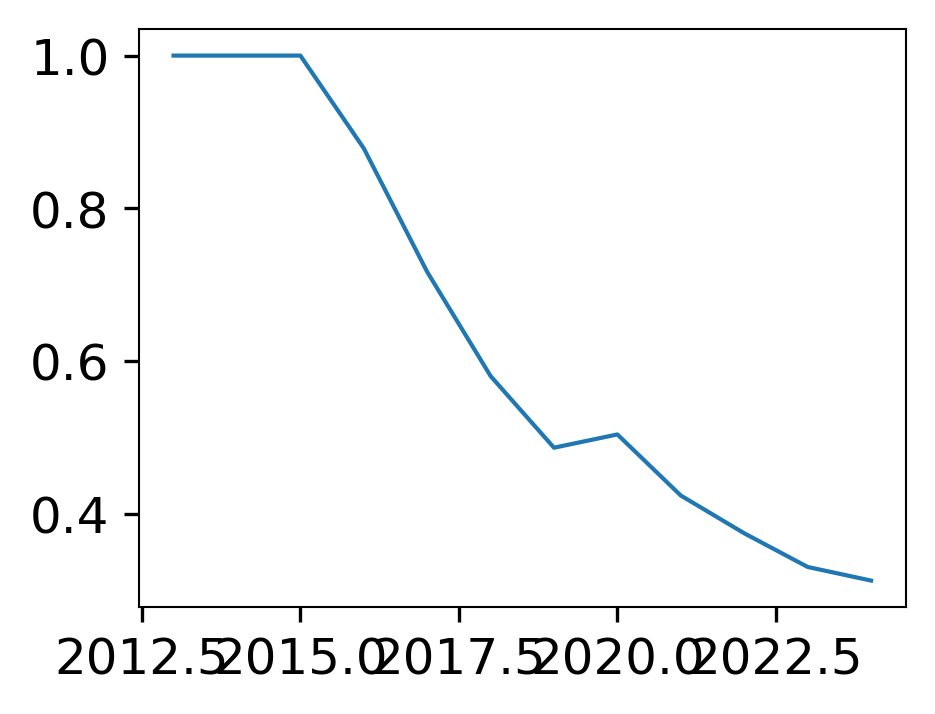

In [185]:
ratio = []
for i in range(2013, 2025):
    ratio.append(plot_citation_monopoly(preprint_year_df[i].dropna()))
plt.plot(range(2013, 2025), ratio)